# Desarrollo y Pruebas (Práctica 1) + Código Base (Práctica 2)

## Práctica 1

### Implementación

Perceptrón con función de activación **sigmoide**, costo de **entropía cruzada** y entrenamiento por **gradiente descendente**. Las entradas se expanden a un polinomio de grado 2 y se normalizan (z-score) antes de entrenar.

**Funciones auxiliares**

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def func_costo(W_1d, Xa, Y):
    # Costo (entropía cruzada) y gradiente del perceptrón con sigmoide
    W = W_1d.reshape(-1, 1)
    Z = Xa @ W
    Yg = 1.0 / (1.0 + np.exp(-Z))              # Función sigmoide (salida entre 0 y 1)
    n = Xa.shape[0]
    eps = np.finfo(float).eps
    Yg = np.clip(Yg, eps, 1.0 - eps)           # Evita log(0)
    J = np.sum(-Y * np.log(Yg) - (1.0 - Y) * np.log(1.0 - Yg)) / n
    E = Yg - Y                                 # Error
    dJdW = (E.T @ Xa).T / n                    # Gradiente
    return J, dJdW.flatten()

def func_polinomio(X, ngrado):
    # Construye la matriz [1 x1 x2 x1x2 x1^2 x2^2 ...] hasta el grado indicado
    m, nvar = X.shape
    Xp = np.ones((m, 1))
    coef = np.zeros((1, nvar))
    for g in range(1, ngrado + 1):
        # Exponentes de los términos cruzados de este grado
        if g - 1 >= 1:
            Atemp = np.hstack((np.arange(g - 1, 0, -1).reshape(-1, 1), np.arange(1, g).reshape(-1, 1)))
        else:
            Atemp = np.empty((0, 2))
        A = np.empty((0, nvar))
        for i in range(nvar - 1):
            for j in range(i + 1, nvar):
                if Atemp.shape[0] > 0:
                    Btemp = np.zeros((g - 1, nvar))
                    Btemp[:, i] = Atemp[:, 0]
                    Btemp[:, j] = Atemp[:, 1]
                    A = np.vstack((A, Btemp))
        A = np.vstack((A, g * np.eye(nvar)))   # Términos puros: x1^g, x2^g
        # Eleva cada variable a su exponente y agrega la columna
        for k in range(A.shape[0]):
            temp = np.ones((m, 1))
            for j in range(nvar):
                temp = temp * (X[:, j].reshape(-1, 1) ** A[k, j])
            Xp = np.hstack((Xp, temp))
        coef = np.vstack((coef, A))
    return Xp, coef.T

def entrenar_gd(Xa, Y, eta, epocas):
    # Gradiente descendente: W <- W - eta * gradiente
    W = np.zeros(Xa.shape[1])
    J_history = np.zeros(epocas)
    for i in range(epocas):
        J_history[i], dJdW = func_costo(W, Xa, Y)
        W = W - eta * dJdW
    return W.reshape(-1, 1), J_history

def predecir(X, W, grado, mu, sigma):
    # Aplica polinomio + normalización con mu/sigma del entrenamiento y la sigmoide
    Xp, _ = func_polinomio(X, grado)
    Xp[:, 1:] = (Xp[:, 1:] - mu) / (sigma + 1e-8)
    prob = 1.0 / (1.0 + np.exp(-(Xp @ W)))
    return prob, np.round(prob).astype(int)     # Probabilidad y clase (0 o 1)

def metricas(Y, Yg):
    # Matriz de confusión y métricas de rendimiento
    y, yg = Y.ravel().astype(int), Yg.ravel().astype(int)
    TP = np.sum((y == 1) & (yg == 1)); TN = np.sum((y == 0) & (yg == 0))
    FP = np.sum((y == 0) & (yg == 1)); FN = np.sum((y == 1) & (yg == 0))
    print(f"TP = {TP} | TN = {TN} | FP = {FP} | FN = {FN}")
    print(f"Accuracy = {(TP + TN) / len(y):.4f} | Precision = {TP / max(TP + FP, 1):.4f} | Recall = {TP / max(TP + FN, 1):.4f}")

def graficar_frontera(data, W, grado, mu, sigma, x1_lim, x2_lim, titulo, ax=None):
    # Dibuja los datos y la región que el modelo asigna a cada clase
    ax = ax or plt.gca()
    x1, x2 = np.meshgrid(np.linspace(*x1_lim, 300), np.linspace(*x2_lim, 300))
    _, clase = predecir(np.column_stack((x1.ravel(), x2.ravel())), W, grado, mu, sigma)
    ax.contourf(x1, x2, clase.reshape(x1.shape), alpha=0.15, cmap="jet")
    G0, G1 = data[data[:, 2] == 0], data[data[:, 2] == 1]
    ax.plot(G0[:, 0], G0[:, 1], "bo", label="Clase 0")
    ax.plot(G1[:, 0], G1[:, 1], "rx", label="Clase 1")
    ax.set(xlabel="X1", ylabel="X2", title=titulo); ax.legend()

**Carga, polinomio y normalización**

In [2]:
data1 = np.loadtxt("data1.txt", delimiter=",")
X1, Y1 = data1[:, 0:2], data1[:, 2].reshape(-1, 1)

grado1 = 2
Xa1, _ = func_polinomio(X1, grado1)

# Normalización z-score (sin la columna de unos)
mu1, sigma1 = Xa1[:, 1:].mean(axis=0), Xa1[:, 1:].std(axis=0)
Xa1[:, 1:] = (Xa1[:, 1:] - mu1) / (sigma1 + 1e-8)

print(f"Datos: {len(Y1)} | Clase 0: {int((Y1 == 0).sum())} | Clase 1: {int((Y1 == 1).sum())}")
print(f"Costo inicial (W = 0): {func_costo(np.zeros(Xa1.shape[1]), Xa1, Y1)[0]:.4f}")

Datos: 100 | Clase 0: 40 | Clase 1: 60
Costo inicial (W = 0): 0.6931


**Entrenamiento** (η = 0.5, 10 000 épocas)

In [3]:
eta, epocas = 0.5, 10000
W1, J1 = entrenar_gd(Xa1, Y1, eta, epocas)
print(f"Costo final: {J1[-1]:.4f}")
print("Pesos:", W1.ravel().round(4))

Costo final: 0.0427
Pesos: [ 9.15    6.6135  4.3451 19.2328 -7.0689 -4.2874]


### Resultados

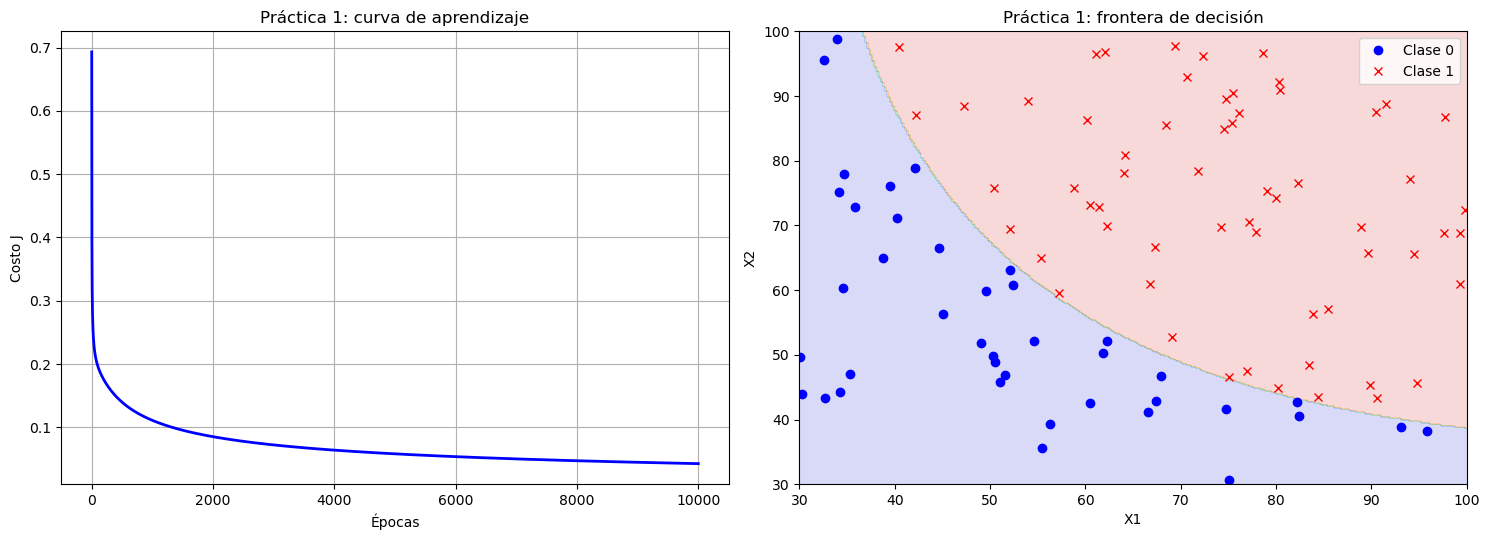

TP = 60 | TN = 40 | FP = 0 | FN = 0
Accuracy = 1.0000 | Precision = 1.0000 | Recall = 1.0000


In [4]:
fig, axs = plt.subplots(1, 2, figsize=(15, 5.5))
axs[0].plot(J1, "b-", lw=2)
axs[0].set(xlabel="Épocas", ylabel="Costo J", title="Práctica 1: curva de aprendizaje"); axs[0].grid(True)
graficar_frontera(data1, W1, grado1, mu1, sigma1, (30, 100), (30, 100), "Práctica 1: frontera de decisión", axs[1])
plt.tight_layout(); plt.show()

_, Yg1 = predecir(X1, W1, grado1, mu1, sigma1)
metricas(Y1, Yg1)

**Análisis**
- El costo baja de 0.693 a 0.043. Cae rápido en las primeras ~200 épocas y luego sigue bajando despacio: como las dos clases se pueden separar por completo, el modelo sigue "afinando" los pesos.
- La frontera de grado 2 es una curva que separa todos los puntos: **0 falsos positivos y 0 falsos negativos** (accuracy, precision y recall = 1.00).
- Estas métricas se calcularon con los mismos datos de entrenamiento, así que miden qué tan bien se ajustó el modelo, no qué tan bien predice datos nuevos.

## Práctica 2

### Implementación (entrenamiento)

Mismo modelo y funciones que en la Práctica 1, ahora con `data2.txt`.

In [5]:
data2 = np.loadtxt("data2.txt", delimiter=",")
X2, Y2 = data2[:, 0:2], data2[:, 2].reshape(-1, 1)

grado2 = 2
Xa2, _ = func_polinomio(X2, grado2)

# Normalización z-score; mu2 y sigma2 se guardan para evaluar datos nuevos
mu2, sigma2 = Xa2[:, 1:].mean(axis=0), Xa2[:, 1:].std(axis=0)
Xa2[:, 1:] = (Xa2[:, 1:] - mu2) / (sigma2 + 1e-8)

# Entrenamiento por gradiente descendente
W2, J2 = entrenar_gd(Xa2, Y2, eta=0.5, epocas=10000)
print(f"Costo final: {J2[-1]:.4f}")
print("Pesos:", W2.ravel().round(4))

_, Yg2 = predecir(X2, W2, grado2, mu2, sigma2)
metricas(Y2, Yg2)

Costo final: 0.3481
Pesos: [-0.2385  1.606   2.1562 -1.6804 -2.9764 -3.3496]
TP = 50 | TN = 51 | FP = 9 | FN = 8
Accuracy = 0.8559 | Precision = 0.8475 | Recall = 0.8621


### Clasificación de nuevos puntos con los pesos obtenidos

Se evalúa el arreglo solicitado con los pesos `W2`. Cada punto pasa por el mismo polinomio y la misma normalización (`mu2`, `sigma2`) del entrenamiento; si la probabilidad es ≥ 0.5 se asigna la clase 1, si no, la clase 0.

In [6]:
# Arreglo solicitado
X_nuevos = np.array([[-1,    1   ],
                     [ 0,    2   ],
                     [ 0,    1   ],
                     [ 0.5,  0.5 ],
                     [ 0.75, 0.75],
                     [ 1,    1   ],
                     [ 2,    3   ],
                     [ 2,   -1   ]])

prob_nuevos, clase_nuevos = predecir(X_nuevos, W2, grado2, mu2, sigma2)

import pandas as pd
tabla_nuevos = pd.DataFrame({"X1": X_nuevos[:, 0], "X2": X_nuevos[:, 1],
                             "Probabilidad clase 1": prob_nuevos.ravel().round(4),
                             "Clase": clase_nuevos.ravel()})
tabla_nuevos

,X1,X2,Probabilidad clase 1,Clase
0,-1.00,1.00,0.0000,0
1,0.00,2.00,0.0000,0
2,0.00,1.00,0.0768,0
3,0.50,0.50,0.7371,1
4,0.75,0.75,0.0010,0
5,1.00,1.00,0.0000,0
6,2.00,3.00,0.0000,0
7,2.00,-1.00,0.0000,0


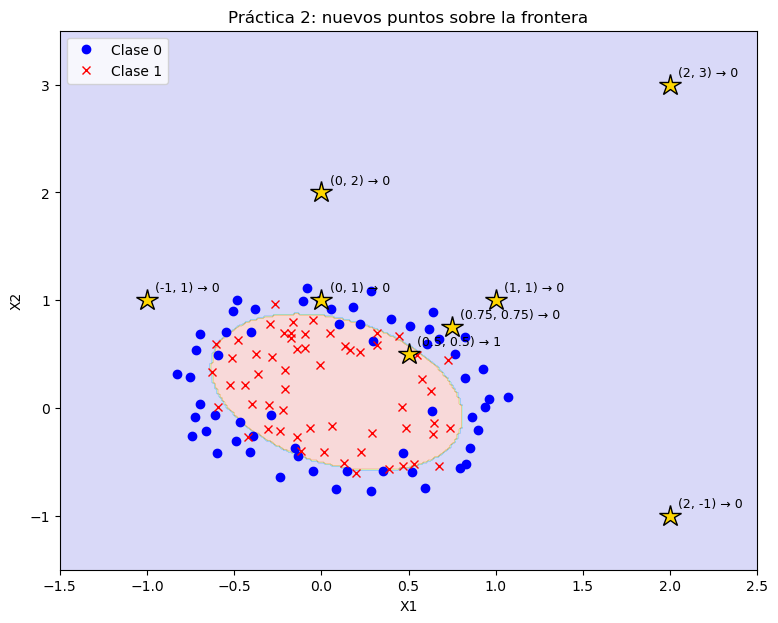

In [7]:
plt.figure(figsize=(9, 7))
graficar_frontera(data2, W2, grado2, mu2, sigma2, (-1.5, 2.5), (-1.5, 3.5), "Práctica 2: nuevos puntos sobre la frontera")
for (x1, x2), cl in zip(X_nuevos, clase_nuevos.ravel()):
    plt.plot(x1, x2, "k*", ms=16, mfc="gold")
    plt.annotate(f"({x1:g}, {x2:g}) → {cl}", (x1, x2), xytext=(6, 6), textcoords="offset points", fontsize=9)
plt.show()

**Análisis**
- Solo **(0.5, 0.5)** se clasifica como clase 1 (probabilidad 0.74), porque cae dentro de la elipse donde están los puntos de clase 1.
- **(0, 1)** queda cerca del borde, pero del lado de afuera (0.08), por lo que es clase 0. Los demás puntos quedan lejos de la zona de clase 1 y su probabilidad es prácticamente 0.
- (−1, 1), (0, 2), (2, 3) y (2, −1) están fuera del rango de los datos de entrenamiento, así que el modelo está extrapolando: su resultado es menos confiable.
- Con grado 2 el entrenamiento llega a un costo de 0.348 y una accuracy de 0.856 (9 FP, 8 FN). La elipse no alcanza a seguir bien el borde irregular de los datos.

## Conclusión personal

En la Práctica 1 vi que el perceptrón con sigmoide separa muy bien dos clases cuando la frontera es sencilla. En la Práctica 2 los datos forman un círculo, y aun así el mismo modelo funciona porque se le agregan los términos del polinomio. También aprendí que, para clasificar puntos nuevos, hay que aplicarles exactamente la misma transformación que a los datos de entrenamiento (polinomio y normalización con la misma media y desviación); si no, los pesos no sirven. Por último, un punto fuera del rango de los datos siempre se va a clasificar, pero eso no significa que el resultado sea confiable.

# Práctica 3: Perceptrón (regresión logística) con polinomio de grado 4

Clasificación de donadores de sangre (`BaseSangre.txt`): la salida es **1 = sí donó** y **0 = no donó**.

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.optimize as opt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split

## Funciones auxiliares

In [9]:
def sigmoide(Z):
    """Función logística: convierte cualquier valor en una probabilidad entre 0 y 1.
    Se recorta Z a [-500, 500] para evitar el 'overflow encountered in exp'."""
    return 1.0 / (1.0 + np.exp(-np.clip(Z, -500, 500)))


def func_costo(W_1d, Xa, Y):
    """
    Costo (entropía cruzada) y gradiente del perceptrón con sigmoide.
    W_1d : pesos como vector 1D (así los envía SciPy)
    Xa   : matriz de entradas con la columna de unos (sesgo) y los términos del polinomio
    Y    : salidas deseadas (0 o 1), columna de n x 1
    Regresa: J (costo, escalar) y dJdW (gradiente, vector 1D)
    """
    W = W_1d.reshape(-1, 1)              # SciPy manda W en 1D; lo pasamos a columna
    Yg = sigmoide(Xa @ W)                # Salida del modelo (probabilidad de clase 1)
    n = Xa.shape[0]                      # Cantidad de datos

    eps = np.finfo(float).eps            # Evita log(0) al calcular el costo
    Yg = np.clip(Yg, eps, 1.0 - eps)

    # Entropía cruzada promedio
    J = np.sum(-Y * np.log(Yg) - (1.0 - Y) * np.log(1.0 - Yg)) / n

    E = Yg - Y                           # Error entre lo obtenido y lo deseado
    dJdW = (E.T @ Xa).T / n              # Gradiente del costo respecto a los pesos
    return J, dJdW.flatten()             # J escalar y gradiente 1D (lo que pide SciPy)


def func_polinomio(X, ngrado):
    """
    Expande X a un polinomio hasta el grado indicado.
    Estructura de salida: [1  x1  x2 ...  x1x2 ...  x1^2  x2^2 ...]
    Regresa: Xp (matriz expandida) y coef (tabla de exponentes de cada columna)
    """
    m, nvar = X.shape
    Xp = np.ones((m, 1))                 # Primera columna de unos (sesgo)
    coef = np.zeros((1, nvar))

    for g in range(1, ngrado + 1):
        # Tabla de exponentes de los términos cruzados de este grado
        if g - 1 >= 1:
            Atemp = np.hstack((np.arange(g - 1, 0, -1).reshape(-1, 1),
                               np.arange(1, g).reshape(-1, 1)))
        else:
            Atemp = np.empty((0, 2))

        A = np.empty((0, nvar))
        for i in range(nvar - 1):
            for j in range(i + 1, nvar):
                if Atemp.shape[0] > 0:
                    Btemp = np.zeros((g - 1, nvar))
                    Btemp[:, i] = Atemp[:, 0]
                    Btemp[:, j] = Atemp[:, 1]
                    A = np.vstack((A, Btemp))
        A = np.vstack((A, g * np.eye(nvar)))   # Términos puros: x1^g, x2^g, ...

        # Eleva cada variable a su exponente y agrega la columna resultante
        for k in range(A.shape[0]):
            temp = np.ones((m, 1))
            for j in range(nvar):
                temp = temp * (X[:, j].reshape(-1, 1) ** A[k, j])
            Xp = np.hstack((Xp, temp))

        coef = np.vstack((coef, A))

    return Xp, coef.T


def metricas(Y, Yg):
    """Matriz de confusión (TP, TN, FP, FN) y métricas Accuracy, Precision y Recall."""
    y, yg = Y.flatten().astype(int), Yg.flatten().astype(int)
    TP = np.sum((y == 1) & (yg == 1))    # Donó y el modelo dijo que donó
    TN = np.sum((y == 0) & (yg == 0))    # No donó y el modelo dijo que no
    FP = np.sum((y == 0) & (yg == 1))    # No donó pero el modelo dijo que sí
    FN = np.sum((y == 1) & (yg == 0))    # Donó pero el modelo dijo que no
    accu = (TP + TN) / (TP + TN + FP + FN)
    prec = TP / (TP + FP) if (TP + FP) > 0 else 0.0
    rec = TP / (TP + FN) if (TP + FN) > 0 else 0.0
    return TP, TN, FP, FN, accu, prec, rec

## Carga y preparación de los datos

Primero se **separa** y después se **normaliza**, para que la media y la desviación no usen información de los datos de prueba.

In [10]:
# Cargar el data set (la primera fila es el encabezado, por eso skiprows=1)
try:
    data = np.loadtxt('BaseSangre.txt', delimiter=',', skiprows=1)
except OSError:
    raise FileNotFoundError("No se encontró 'BaseSangre.txt' en la carpeta del notebook.")

X = data[:, 0:4]                         # 4 variables de entrada
Y = data[:, 4].reshape(-1, 1)            # Salida: 1 = donó, 0 = no donó
m = X.shape[0]
print(f"Datos totales: {m}")

# Partición 80 % entrenamiento / 20 % prueba (random_state fijo para repetir resultados)
Xtrain, Xtest, Ytrain, Ytest = train_test_split(X, Y, test_size=0.2, random_state=42)
print(f"Entrenamiento: {Xtrain.shape[0]} | Prueba: {Xtest.shape[0]}")

# Normalización z-score (necesaria para gradiente / BFGS con polinomios de grado alto).
# mu y sigma se calculan SOLO con entrenamiento y se aplican a ambos conjuntos.
mu = np.mean(Xtrain, axis=0)
sigma = np.std(Xtrain, axis=0)
Xtrain = (Xtrain - mu) / (sigma + 1e-8)
Xtest = (Xtest - mu) / (sigma + 1e-8)

# Polinomio de grado 4 (el mismo para entrenamiento y prueba)
grado = 4
Xa, coeficientes = func_polinomio(Xtrain, grado)
Xatest, _ = func_polinomio(Xtest, grado)
print(f"Columnas del polinomio (pesos a entrenar): {Xa.shape[1]}")

Datos totales: 748
Entrenamiento: 598 | Prueba: 150
Columnas del polinomio (pesos a entrenar): 53


## Entrenamiento

In [11]:
W = np.zeros(Xa.shape[1])                # Pesos inicializados en cero

print("Optimizando pesos...")
options = {'maxiter': 1000, 'disp': True}
resultado = opt.minimize(func_costo, W, args=(Xa, Ytrain),   # Se usa Ytrain: mismas filas que Xa
                         method='BFGS', jac=True, options=options)

Wopt = resultado.x.reshape(-1, 1)        # Pesos óptimos
Jopt = resultado.fun                     # Costo final
print(f"Pesos = \n{Wopt}")
print(f"J_opt = {Jopt}")

Optimizando pesos...
Optimization terminated successfully.
         Current function value: 0.433399
         Iterations: 190
         Function evaluations: 197
         Gradient evaluations: 197
Pesos = 
[[-1.3495037 ]
 [-2.05597445]
 [ 0.41728633]
 [ 0.41728633]
 [ 0.31499931]
 [-0.20577517]
 [-0.20577517]
 [ 0.71929543]
 [-0.67436107]
 [ 0.47140785]
 [ 0.47140785]
 [ 0.41706118]
 [-0.67436107]
 [-0.67436107]
 [ 0.15988639]
 [ 0.74500514]
 [-0.09007613]
 [ 0.74500514]
 [-0.09007613]
 [-0.96268263]
 [ 1.31732651]
 [ 0.1551436 ]
 [ 0.1551436 ]
 [ 0.08572432]
 [-0.01266108]
 [ 0.08572432]
 [-0.01266108]
 [ 1.1248418 ]
 [ 0.1551436 ]
 [ 0.1551436 ]
 [-0.96721238]
 [-0.13970675]
 [-0.24731782]
 [ 0.00313954]
 [-0.13970675]
 [-0.24731782]
 [ 0.00313954]
 [-0.55997501]
 [ 0.26831862]
 [-0.48957965]
 [ 0.01049664]
 [ 0.01049664]
 [ 0.01049664]
 [-0.25990933]
 [ 0.35109926]
 [-0.20317547]
 [-0.25990933]
 [ 0.35109926]
 [-0.20317547]
 [-0.24129743]
 [ 0.01049664]
 [ 0.01049664]
 [ 0.32473219]]

## Evaluación: entrenamiento y prueba

In [12]:
# --- Entrenamiento ---
Yg_train = np.round(sigmoide(Xa @ Wopt))             # Clase predicha (0 o 1)
TP, TN, FP, FN, Accu, Pre, Rec = metricas(Ytrain, Yg_train)
print("Entrenamiento")
print(f"  TP={TP} | TN={TN} | FP={FP} | FN={FN}")
print(f"  Falsos Positivos | Falsos Negativos: [{FP}, {FN}]")

# --- Prueba (datos que el modelo nunca vio) ---
Yg_test = np.round(sigmoide(Xatest @ Wopt))
TPt, TNt, FPt, FNt, Accut, Pret, Rect = metricas(Ytest, Yg_test)
print("Prueba")
print(f"  TP={TPt} | TN={TNt} | FP={FPt} | FN={FNt}")

print("\nComparativa [Accuracy | Precision | Recall]:")
print(f"  Entrenamiento: [{Accu:.4f} | {Pre:.4f} | {Rec:.4f}]")
print(f"  Prueba:        [{Accut:.4f} | {Pret:.4f} | {Rect:.4f}]")

Entrenamiento
  TP=56 | TN=429 | FP=28 | FN=85
  Falsos Positivos | Falsos Negativos: [28, 85]
Prueba
  TP=12 | TN=105 | FP=8 | FN=25

Comparativa [Accuracy | Precision | Recall]:
  Entrenamiento: [0.8110 | 0.6667 | 0.3972]
  Prueba:        [0.7800 | 0.6000 | 0.3243]


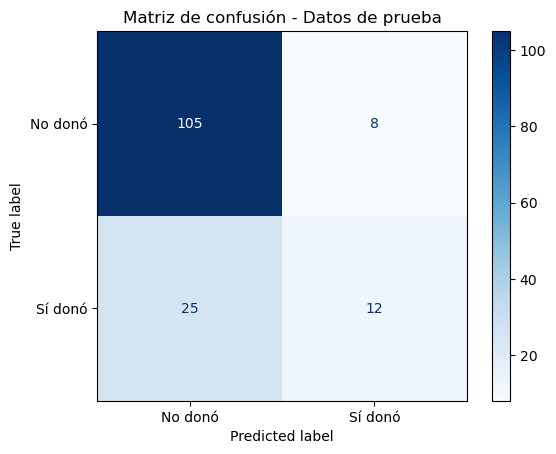

In [13]:
# Matriz de confusión de los datos de prueba
cm = confusion_matrix(Ytest.flatten().astype(int), Yg_test.flatten().astype(int))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No donó", "Sí donó"]).plot(cmap="Blues", values_format="d")
plt.title("Matriz de confusión - Datos de prueba")
plt.show()

## Distribución de clases

Distribución de clases en el conjunto de prueba:
  Clase 0: 113 muestras (75.33 %)
  Clase 1: 37 muestras (24.67 %)

Accuracy de 'siempre predecir la clase mayoritaria': 0.7533
Accuracy del modelo en prueba:                       0.7800


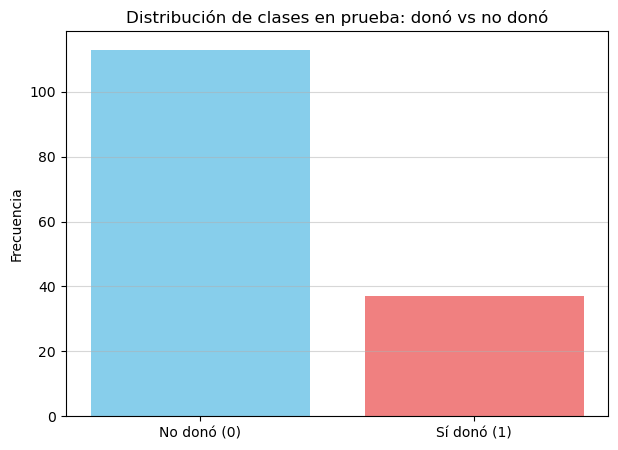

In [14]:
Ytest_flat = Ytest.flatten().astype(int)
clases, counts = np.unique(Ytest_flat, return_counts=True)

print("Distribución de clases en el conjunto de prueba:")
for c, cnt in zip(clases, counts):
    # El porcentaje se calcula sobre el total de PRUEBA (no sobre m), para que sume 100 %
    print(f"  Clase {c}: {cnt} muestras ({cnt / len(Ytest_flat) * 100:.2f} %)")

# Referencia: accuracy que se obtendría prediciendo siempre la clase mayoritaria
print(f"\nAccuracy de 'siempre predecir la clase mayoritaria': {counts.max() / len(Ytest_flat):.4f}")
print(f"Accuracy del modelo en prueba:                       {Accut:.4f}")

# Gráfica de barras
plt.figure(figsize=(7, 5))
plt.bar(clases, counts, color=['skyblue', 'lightcoral'])
plt.xticks(clases, ["No donó (0)", "Sí donó (1)"])
plt.title("Distribución de clases en prueba: donó vs no donó")
plt.ylabel("Frecuencia")
plt.grid(axis="y", alpha=0.5)
plt.show()

## Pruebas y resultados: casos con diferentes datos de entrada

Se tomó como base `Perceptron_3.py` (Módulo 2), donde las entradas se eligen con `X = data[:, 0:2]` (Recency y Frequency) y un polinomio de grado 3. Aquí se repite el entrenamiento cambiando **qué variables entran a la red** y el **grado del polinomio**, manteniendo todo lo demás igual que en el modelo principal:

- Partición 80 % entrenamiento / 20 % prueba con `random_state=42` (los mismos datos de prueba en todos los casos).
- Normalización z-score con la media y desviación del entrenamiento.
- Pesos iniciales en cero y optimización con BFGS (máx. 1000 iteraciones).

Variables disponibles: **Recency** (meses desde la última donación), **Frequency** (número de donaciones), **Monetary** (c.c. de sangre donada) y **Time** (meses desde la primera donación).

In [15]:
import pandas as pd

nombres = ["Recency", "Frequency", "Monetary", "Time"]

# Casos: (columnas de entrada, grado del polinomio)
casos = [([0, 1],       3),   # Mismas entradas y grado que Perceptron_3.py
         ([0, 3],       3),
         ([1, 3],       3),
         ([0],          3),
         ([0, 1, 2, 3], 1),
         ([0, 1, 2, 3], 2),
         ([0, 1, 2, 3], 4),   # Modelo principal de la Práctica 3
         ([0, 1, 3],    4)]   # Mismo modelo sin Monetary

def evaluar_caso(cols, grado):
    """Entrena la red con las columnas y el grado indicados; regresa las métricas."""
    Xc = data[:, cols]
    Yc = data[:, 4].reshape(-1, 1)
    Xtr, Xte, Ytr, Yte = train_test_split(Xc, Yc, test_size=0.2, random_state=42)

    # Normalización con los datos de entrenamiento
    mu_c, sigma_c = Xtr.mean(axis=0), Xtr.std(axis=0)
    Xtr = (Xtr - mu_c) / (sigma_c + 1e-8)
    Xte = (Xte - mu_c) / (sigma_c + 1e-8)

    Xa_c, _ = func_polinomio(Xtr, grado)
    Xat_c, _ = func_polinomio(Xte, grado)

    res = opt.minimize(func_costo, np.zeros(Xa_c.shape[1]), args=(Xa_c, Ytr),
                       method='BFGS', jac=True, options={'maxiter': 1000})
    W_c = res.x.reshape(-1, 1)

    _, _, _, _, acc_tr, _, rec_tr = metricas(Ytr, np.round(sigmoide(Xa_c @ W_c)))
    TP_c, TN_c, FP_c, FN_c, acc_te, pre_te, rec_te = metricas(Yte, np.round(sigmoide(Xat_c @ W_c)))

    return {"Entradas": ", ".join(nombres[c] for c in cols),
            "Grado": grado,
            "Pesos": Xa_c.shape[1],
            "Costo J": round(res.fun, 4),
            "Accuracy entr.": round(acc_tr, 4),
            "Recall entr.": round(rec_tr, 4),
            "TP": TP_c, "TN": TN_c, "FP": FP_c, "FN": FN_c,
            "Accuracy prueba": round(acc_te, 4),
            "Precision prueba": round(pre_te, 4),
            "Recall prueba": round(rec_te, 4)}

tabla_casos = pd.DataFrame([evaluar_caso(c, g) for c, g in casos])
tabla_casos.index = [f"Caso {i}" for i in range(1, len(casos) + 1)]
tabla_casos

,Entradas,Grado,Pesos,Costo J,Accuracy entr.,Recall entr.,TP,TN,FP,FN,Accuracy prueba,Precision prueba,Recall prueba
Caso 1,"Recency, Frequency",3,10,0.4756,0.7692,0.1702,2,104,9,35,0.7067,0.1818,0.0541
Caso 2,"Recency, Time",3,10,0.4870,0.7659,0.0142,1,112,1,36,0.7533,0.5000,0.0270
Caso 3,"Frequency, Time",3,10,0.4738,0.7759,0.2057,5,109,4,32,0.7600,0.5556,0.1351
Caso 4,Recency,3,4,0.4942,0.7642,0.0000,0,113,0,37,0.7533,0.0000,0.0000
Caso 5,"Recency, Frequency, Monetary, Time",1,5,0.4705,0.7742,0.1206,4,110,3,33,0.7600,0.5714,0.1081
Caso 6,"Recency, Frequency, Monetary, Time",2,15,0.4553,0.7993,0.2695,6,107,6,31,0.7533,0.5000,0.1622
Caso 7,"Recency, Frequency, Monetary, Time",4,53,0.4334,0.8110,0.3972,12,105,8,25,0.7800,0.6000,0.3243
Caso 8,"Recency, Frequency, Time",4,31,0.4334,0.8110,0.3972,12,105,8,25,0.7800,0.6000,0.3243


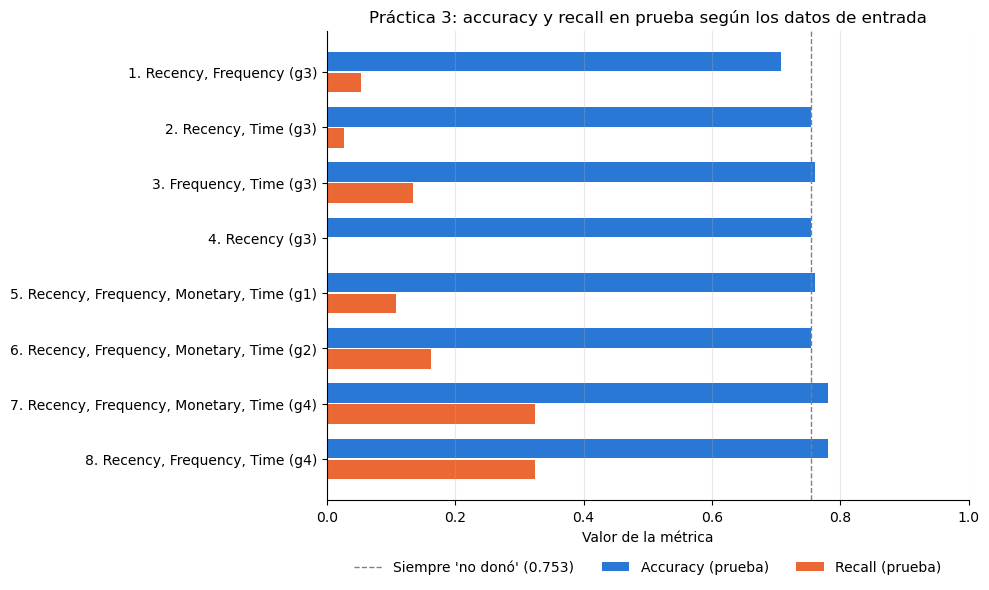

In [16]:
# Comparación de los casos en los datos de prueba
fig, ax = plt.subplots(figsize=(10, 6))
etiquetas = [f"{i}. {e} (g{g})" for i, (e, g) in
             enumerate(zip(tabla_casos["Entradas"], tabla_casos["Grado"]), start=1)]
y_pos = np.arange(len(tabla_casos))
alto = 0.38

ax.barh(y_pos - alto / 2, tabla_casos["Accuracy prueba"], height=alto - 0.03,
        color="#2a78d6", label="Accuracy (prueba)")
ax.barh(y_pos + alto / 2, tabla_casos["Recall prueba"], height=alto - 0.03,
        color="#eb6834", label="Recall (prueba)")

# Referencia: predecir siempre "no donó"
base = (Ytest == 0).mean()
ax.axvline(base, color="gray", ls="--", lw=1, label=f"Siempre 'no donó' ({base:.3f})")

ax.set_yticks(y_pos, etiquetas)
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("Valor de la métrica")
ax.set_title("Práctica 3: accuracy y recall en prueba según los datos de entrada")
ax.grid(axis="x", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3, frameon=False)
plt.tight_layout()
plt.show()

**Análisis de los casos**

- **Recency sola (caso 4):** la red siempre responde "no donó" (TP = 0, recall = 0). Su accuracy de 0.753 es exactamente la de predecir siempre la clase mayoritaria, así que con una sola variable la red no aprende nada útil. Es el ejemplo más claro de que la accuracy por sí sola engaña.
- **Dos variables (casos 1 a 3):** Recency + Time casi no detecta donadores (recall 0.027). Frequency + Time es el mejor de los pares (recall 0.135). Las mismas entradas y grado de `Perceptron_3.py` (Recency + Frequency, grado 3) dan la accuracy más baja de la tabla (0.707, por debajo de la referencia) y un recall de solo 0.054.
- **Las cuatro variables (casos 5 a 7):** al subir el grado de 1 a 4, el costo baja (0.471 → 0.433) y el recall en prueba sube de 0.108 a 0.324. El grado 4 (caso 7) es el mejor de la tabla: accuracy 0.78 y 12 donadores bien detectados de 37.
- **Sin Monetary (caso 8):** da **exactamente** los mismos resultados que el caso 7, pero con 31 pesos en lugar de 53. Esto pasa porque en los datos `Monetary = 250 × Frequency` (cada donación son 250 c.c.), así que Monetary no aporta información nueva. Por la misma razón, en los pesos del modelo principal aparecen valores repetidos.
- **En resumen:** lo que más mejora la red es combinar Recency, Frequency y Time con un polinomio de grado alto. Aun así, el recall máximo es de 0.32: el modelo sigue sin reconocer a la mayoría de los donadores, en parte porque solo el 24 % de los datos son de la clase 1.

## Conclusión personal Esmer

En estas tres prácticas fui entendiendo cómo funciona el perceptrón y cómo se puede aplicar a diferentes problemas. En la primera práctica aprendí a separar dos clases con una frontera sencilla; en la segunda, a clasificar datos con una frontera más compleja usando polinomios, y también entendí que los datos nuevos deben tener las mismas transformaciones que los datos de entrenamiento.

La tercera práctica fue la que más me ayudó a entender que no basta con que un modelo tenga un buen porcentaje de accuracy. Aunque el resultado fue de 78 %, el recall de 32 % me hizo ver que el modelo todavía tenía dificultades para identificar a las personas que sí donaron. Por eso aprendí que es importante revisar diferentes métricas y la matriz de confusión para saber qué tan bien está funcionando el modelo. También entendí por qué es importante separar los datos de entrenamiento y prueba antes de normalizarlos, para evitar afectar los resultados. En general, estas prácticas me ayudaron a comprender mejor cómo se entrena un modelo y que, para saber si realmente funciona, no solo hay que fijarse en los resultados, sino también en cómo se obtuvieron.

## Conclusión personal Fer

Al probar la red de la Práctica 3 con diferentes datos de entrada me di cuenta de que elegir bien las variables importa tanto como el algoritmo. Con una sola variable la red siempre contestaba "no donó" y aun así tenía 75 % de accuracy, lo que me enseñó que esa métrica puede engañar cuando una clase es mucho más común que la otra; por eso hay que revisar también el recall y la matriz de confusión. También vi que agregar variables y subir el grado del polinomio ayuda, pero no todas las variables aportan: Monetary resultó ser lo mismo que Frequency multiplicado por 250, y quitarla dio exactamente el mismo resultado con menos pesos. Me quedo con que, antes de entrenar, vale la pena conocer bien los datos.